[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ContextLab/timecorr/blob/master/docs/tutorial/trajectories.ipynb)

# Trajectories of features at orders 1 to 4

This tutorial computes features of orders 1 to 4 with `tc.features` on three real datasets from different domains, reduces each order to three dimensions, and animates the result as a trajectory with [hypertools](https://hypertools.readthedocs.io/). You will see how to compare the shape of a dataset's trajectory across orders.

**Data.**

- *Brain activity during story listening*: the HTFA node weights of 36 people listening to a story (Simony et al., 2016, [doi:10.1038/ncomms12141](https://doi.org/10.1038/ncomms12141)), as analyzed by Owen, Chang & Manning (2021, [doi:10.1038/s41467-021-25876-x](https://doi.org/10.1038/s41467-021-25876-x)). The loading code is that of the [HTFA tutorial](htfa_network_animations.ipynb), which describes the data; the archive is 460 MB.
- *Stock market*: the daily log returns of the 49 US industry portfolios of the [Kenneth R. French Data Library](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/data_library.html), 2005 to 2024, as in the [stock-market tutorial](stocks.ipynb).
- *Human movement*: trial 2 of subject 86 of the [CMU Graphics Lab Motion Capture Database](http://mocap.cs.cmu.edu/) ("walk, squats, run, stretch, jumps, punches, and drinking", [trial list](http://mocap.cs.cmu.edu/search.php?subjectnumber=86)): the joint angles of one person, recorded at 120 frames per second. The data used here were obtained from mocap.cs.cmu.edu; the database was created with funding from NSF EIA-0196217.

Downloads are cached in the folder set by the `TIMECORR_DATA` environment variable (default `~/timecorr_data`). The notebook takes about 5 minutes on a 12-core laptop, most of it rendering the videos, and should take about 15 minutes on a free Colab runtime (an estimate, not measured there); the last cell prints its run time.

In [1]:
# On Google Colab, install timecorr, hypertools and an ffmpeg binary (this cell does nothing elsewhere).
# It installs timecorr 0.3.0 or later from PyPI; if that release is not on PyPI yet,
# it installs from GitHub instead.
import sys
if "google.colab" in sys.modules:
    !pip install -q "hypertools>=1.1" imageio-ffmpeg
    !pip install -q "timecorr>=0.3.0" 2>/dev/null || pip install -q "git+https://github.com/ContextLab/timecorr.git@master"

In [2]:
import hashlib
import io
import logging
import os
import subprocess
import time
import urllib.request
import warnings
import zipfile
from pathlib import Path

import hypertools as hyp
import imageio_ffmpeg
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.io
from IPython.display import HTML, Image, Video, display
from joblib import Parallel, delayed
from matplotlib import font_manager
from PIL import Image as PILImage, ImageDraw, ImageFont

import timecorr as tc

%matplotlib inline
NOTEBOOK_START = time.time()
DATA_ROOT = Path(os.environ.get('TIMECORR_DATA', Path.home() / 'timecorr_data'))
print('timecorr', tc.__version__, '| hypertools', hyp.__version__)


def sha256(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for chunk in iter(lambda: f.read(1 << 20), b''):
            h.update(chunk)
    return h.hexdigest()


def download(url, path):
    path.parent.mkdir(parents=True, exist_ok=True)
    if not path.exists():
        tmp = path.with_suffix('.part')
        try:
            urllib.request.urlretrieve(url, tmp)
        except OSError as err:
            raise RuntimeError(f'could not download {url} ({err})') from err
        tmp.replace(path)
    return path

timecorr 0.3.0 | hypertools 1.1.0


## 1. Loading the three datasets

**Story listening.** As in the HTFA tutorial: the node weights of the intact condition, the nodes whose weights are never constant, and 100 of them spread over the brain by farthest-point sampling. The result is one matrix (timepoints by nodes) per participant.

In [3]:
fit_path = DATA_ROOT / 'pieman' / 'pieman_posterior_K700.mat'     # shared with the HTFA tutorial
if not fit_path.exists():
    archive = download('https://drive.usercontent.google.com/download'
                       '?id=1CZYe8eyAkZFuLqfwwlKoeijgkjdW6vFs&export=download&confirm=t',
                       DATA_ROOT / 'pieman' / 'data.zip')
    with zipfile.ZipFile(archive) as z, z.open('data/pieman_posterior_K700.mat') as src, \
            open(fit_path, 'wb') as dst:
        while chunk := src.read(1 << 20):
            dst.write(chunk)
    archive.unlink()
if sha256(fit_path) != '870179316f127776ff78096c361df6b1c5c7957d6456deb26b5489bcee6c0793':
    raise RuntimeError(f'{fit_path} does not match its checksum; delete it and run this cell again')

post = scipy.io.loadmat(fit_path)['posterior'][0, 0]
names = [str(n[0]) for n in post['subjects_names'][0]]
centers = np.asarray(post['centers'][0, 0]['mean'], dtype=float)
intact = sorted((i for i, n in enumerate(names) if n.startswith('intact_')),
                key=lambda i: int(names[i].split('_s')[1].split('.')[0]))
weights = np.stack([post['subjects'][0, i]['image_weights'][0, 0]['mean'][0, 0] for i in intact])
del post
usable = np.flatnonzero(~(weights.std(axis=1) < 1e-6).any(axis=0))


def farthest_points(points, k):
    chosen = [int(np.argmin(np.linalg.norm(points - points.mean(axis=0), axis=1)))]
    dist = np.linalg.norm(points - points[chosen[0]], axis=1)
    for _ in range(k - 1):
        chosen.append(int(np.argmax(dist)))
        dist = np.minimum(dist, np.linalg.norm(points - points[chosen[-1]], axis=1))
    return np.array(chosen)


nodes = usable[farthest_points(centers[usable], 100)]
story = [w[:, nodes] for w in weights]
print(f'story listening: {len(story)} participants, each {story[0].shape[0]} timepoints by {story[0].shape[1]} nodes')

story listening: 36 participants, each 300 timepoints by 100 nodes


**Stock market.** As in the stock-market tutorial: the value-weighted daily returns of the 49 industries, 2005 to 2024, as log returns.

In [4]:
zip_path = download('https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/'
                    '49_Industry_Portfolios_daily_CSV.zip', DATA_ROOT / 'french' / '49_Industry_Portfolios_daily_CSV.zip')
with zipfile.ZipFile(zip_path) as z:
    lines = z.read(z.namelist()[0]).decode('latin-1').splitlines()
first = next(i for i, line in enumerate(lines) if 'Average Value Weighted Returns -- Daily' in line)
last = next(i for i in range(first + 1, len(lines)) if not lines[i].strip())
table = pd.read_csv(io.StringIO('\n'.join(lines[first + 1:last])), index_col=0)
table.index = pd.to_datetime(table.index.astype(str).str.strip(), format='%Y%m%d')
table = table.loc['2005-01-01':'2024-12-31']
table = table.loc[:, (table > -99.99).all()]        # drop industries with missing values
stock_dates = table.index
stocks = np.log1p(table.values / 100)
print(f'stock market: {stocks.shape[0]} trading days by {stocks.shape[1]} industries')

stock market: 5033 trading days by 49 industries


**Human movement.** The motion file (AMC format) lists, for every frame, the angles of each joint in degrees. The cell keeps the joint angles (not the position and orientation of the body as a whole), drops the angles that never change, removes the 360-degree jumps of angles that wrap around, and averages blocks of 10 frames (12 samples per second).

In [5]:
amc = download('http://mocap.cs.cmu.edu/subjects/86/86_02.amc', DATA_ROOT / 'cmu_mocap' / '86_02.amc')
if sha256(amc) != 'c89f384eddeee3bf1baf7311058d36b10fcdd70c900ba8d30197a391e61cd990':
    raise RuntimeError(f'{amc} does not match its checksum; delete it and run this cell again')

frames, current = [], None
for line in amc.read_text().splitlines():
    if line.startswith(('#', ':')):
        continue
    fields = line.split()
    if len(fields) == 1 and fields[0].isdigit():         # a frame number starts a new frame
        current = {}
        frames.append(current)
    elif current is not None:
        current[fields[0]] = [float(v) for v in fields[1:]]
channels = [(joint, i) for joint, values in frames[0].items() if joint != 'root' for i in range(len(values))]
angles = np.array([[f[joint][i] for joint, i in channels] for f in frames])
angles = angles[:, angles.std(axis=0) > 1e-3]          # angles that change
angles = np.unwrap(angles, period=360, axis=0)
n = len(angles) // 10 * 10
movement = angles[:n].reshape(-1, 10, angles.shape[1]).mean(axis=1)
MOVEMENT_RATE = 12                                      # samples per second
print(f'human movement: {len(frames)} frames ({len(frames) / 120:.1f} s) -> '
      f'{movement.shape[0]} samples by {movement.shape[1]} joint angles')

human movement: 10617 frames (88.5 s) -> 1061 samples by 50 joint angles


## 2. Features of orders 1 to 4

For each dataset, `tc.features(data, order=4, return_info=True)` with the defaults. For the story-listening data, the features are computed per participant and then averaged over participants. The table gives the number of columns of each order's features; the warnings that `tc.features` issues are printed once per dataset.

The first and last `EDGE` timepoints are then left out: there the kernels reach past the ends of the recording, and the features there are far from those in the middle (the HTFA tutorial shows this for the story-listening data), which would squeeze the rest of a trajectory into a corner of the plot.

In [6]:
DATASETS = {'Story listening': story, 'Stock market': stocks, 'Human movement': movement}
EDGE = 25
features = {}
for name, data in DATASETS.items():
    start = time.time()
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        X, info = tc.features(data, order=4, return_info=True)
    if isinstance(data, list):
        X = [np.mean(x, axis=0) for x in X]
    features[name] = [x[EDGE:len(x) - EDGE] for x in X]
    widths = ', '.join(f'X[{k}]: {X[k].shape[1]}' for k in range(1, 5))
    print(f'{name}: {time.time() - start:.0f} s; columns {widths}')
    for message in sorted({str(w.message) for w in caught}):
        print(f'  warning ({sum(str(w.message) == message for w in caught)}x): {message}')

Story listening: 49 s; columns X[1]: 100, X[2]: 200, X[3]: 8, X[4]: 8
  warning (1x): WeightedStrength: 13 output columns are constant over time (zero variance, or a range within round-off of 0, set to the column's mean), for example because every weight is 0; returned as computed otherwise.
  warning (1x): WeightedStrength: 8 output columns are constant over time (zero variance, or a range within round-off of 0, set to the column's mean), for example because every weight is 0; returned as computed otherwise.


Stock market: 9 s; columns X[1]: 49, X[2]: 18, X[3]: 18, X[4]: 18
  warning (3x): WeightedStrength: 1 output column is constant over time (zero variance, or a range within round-off of 0, set to the column's mean), for example because every weight is 0; returned as computed otherwise.


Human movement: 1 s; columns X[1]: 50, X[2]: 8, X[3]: 8, X[4]: 8
  warning (2x): WeightedStrength: 1 output column is constant over time (zero variance, or a range within round-off of 0, set to the column's mean), for example because every weight is 0; returned as computed otherwise.


## 3. The trajectories

Each panel below reduces one order's features to three dimensions with hypertools (its default, incremental PCA, fit separately for each order) and draws them as a line through time. Rows are datasets, columns are orders.

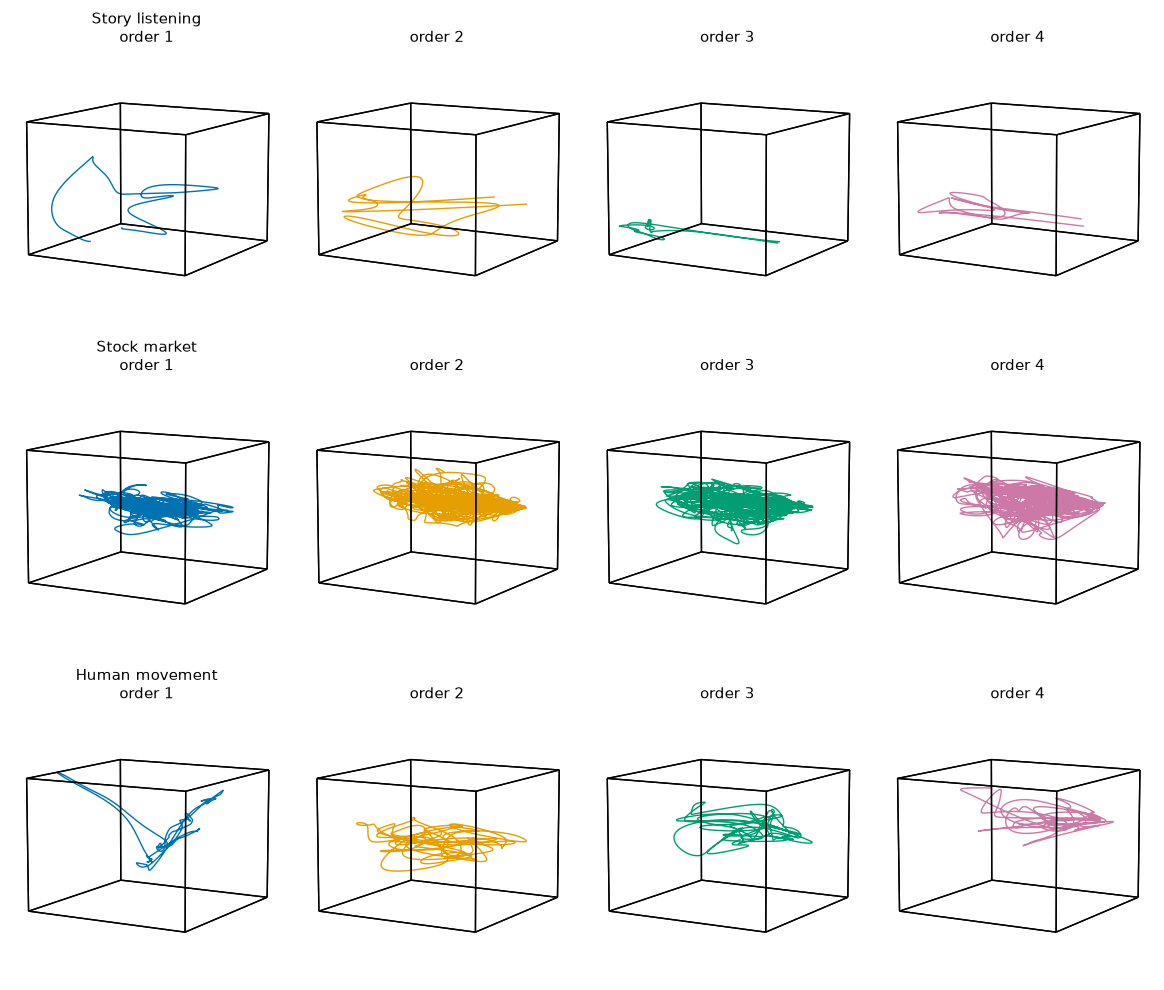

In [7]:
COLORS = ['#0072B2', '#E69F00', '#009E73', '#CC79A7']          # one color per order


def drop_font_weight_message():
    # hypertools lists fallback fonts for non-Latin text; on macOS one of them makes matplotlib
    # log "findfont: Failed to find font weight ..." (harmless); only that message is dropped
    logging.getLogger('matplotlib.font_manager').addFilter(
        lambda record: 'Failed to find font weight' not in record.getMessage())


def hypertools_quietly():
    # hypertools checks at import whether the notebook can show interactive matplotlib figures
    # and, if not, warns on every hyp.plot call; these figures are drawn off-screen, so only
    # those messages are dropped
    drop_font_weight_message()
    warnings.filterwarnings('ignore', message='The `ipympl` package is not installed')
    warnings.filterwarnings('ignore', message='Failed to switch to interactive')


hypertools_quietly()

fig, axes = plt.subplots(3, 4, figsize=(14, 10), subplot_kw={'projection': '3d'})
for row, (name, X) in enumerate(features.items()):
    for k in range(1, 5):
        ax = axes[row, k - 1]
        hyp.plot(X[k], ax=ax, show=False, backend='matplotlib', color=COLORS[k - 1], linewidth=1)
        ax.set_title(f'{name}\norder {k}' if k == 1 else f'order {k}', fontsize=11)
plt.tight_layout()
plt.show()

## 4. Animations

One video per dataset, with the four orders side by side. Each order is animated by `hyp.plot(..., animate=True)` (the camera turns slowly; a faint trail shows the path so far); the notebook draws the frames of the four animations with `draw_frame`, tiles them into one 1920 x 1080 frame with the time in the caption, and encodes the frames to H.264 at 30 frames per second with the ffmpeg binary of `imageio-ffmpeg`. Frames are drawn in parallel (up to three workers). In the documentation the videos are separate files linked below; elsewhere (for example on Colab) they are saved in `tutorial_media/` and shown in the notebook.

In [8]:
# Inside the documentation sources (docs/tutorial), videos go to docs/_static/tutorial_media and
# are linked; anywhere else (for example on Colab), they go to ./tutorial_media and are embedded.
IN_DOCS = (Path('..') / 'conf.py').exists() and (Path('..') / '_static').is_dir()
MEDIA_DIR = Path('..') / '_static' / 'tutorial_media' if IN_DOCS else Path('tutorial_media')
MEDIA_DIR.mkdir(parents=True, exist_ok=True)
N_JOBS = min(3, os.cpu_count() or 1)                       # parallel frame-drawing workers


def show_video(path):
    if IN_DOCS:
        src = Path(os.path.relpath(path)).as_posix()
        display(HTML(f'<video src="{src}" controls loop muted playsinline preload="metadata" '
                     f'style="width: 100%; max-width: 960px;"></video>'))
    else:
        display(Video(str(path), embed=True, width=960,
                      html_attributes='controls loop muted playsinline'))
FPS, CRF = 30, 25
PANEL = (960, 510)                                           # pixels per order; caption band on top
FONT = str(font_manager.findfont('DejaVu Sans'))


def animations(X, duration):
    return [hyp.plot(X[k], animate=True, duration=duration, frame_rate=FPS, tail_duration=2,
                     chemtrails=True, rotations=0.5, zoom=2.5, size=(PANEL[0] / 100, PANEL[1] / 100),
                     show=False, backend='matplotlib', color=COLORS[k - 1], linewidth=2,
                     title=f'Order {k}', title_kwargs={'fontsize': 18})
            for k in range(1, 5)]


def render_chunk(X, duration, caption, title, frame_ids, folder):
    hypertools_quietly()                                     # in each worker process
    anims = animations(X, duration)
    n_frames, n_rows = anims[0].n_frames, len(X[1])
    font, small = ImageFont.truetype(FONT, 30), ImageFont.truetype(FONT, 24)
    for i in frame_ids:
        tile = PILImage.new('RGB', (1920, 1080), 'white')
        for k, a in enumerate(anims):
            a.draw_frame(i)
            buf = io.BytesIO()
            a.figure.savefig(buf, format='png', dpi=100, facecolor='white')
            tile.paste(PILImage.open(buf).convert('RGB').resize(PANEL), ((k % 2) * 960, 60 + (k // 2) * 510))
        draw = ImageDraw.Draw(tile)
        draw.text((30, 14), title, fill='#222222', font=font)
        row = round(i / max(1, n_frames - 1) * (n_rows - 1))   # the row each animation has reached
        draw.text((1890, 18), caption(row), fill='#444444', font=small, anchor='ra')
        tile.save(folder / f'{i:05d}.png')


def render(name, duration, caption):
    X = features[name]
    folder = DATA_ROOT / 'frames' / name.replace(' ', '_').lower()
    folder.mkdir(parents=True, exist_ok=True)
    for old in folder.glob('*.png'):
        old.unlink()
    n_frames = int(round(duration * FPS))
    start = time.time()
    Parallel(n_jobs=N_JOBS)(delayed(render_chunk)(X, duration, caption, f'{name}: features of orders 1 to 4',
                                             chunk, folder)
                       for chunk in np.array_split(np.arange(n_frames), 12))
    path = MEDIA_DIR / f'trajectories_{name.replace(" ", "_").lower()}.mp4'
    subprocess.run([imageio_ffmpeg.get_ffmpeg_exe(), '-y', '-loglevel', 'error', '-framerate', str(FPS),
                    '-i', str(folder / '%05d.png'), '-c:v', 'libx264', '-preset', 'slow', '-crf', str(CRF),
                    '-pix_fmt', 'yuv420p', '-movflags', '+faststart', str(path)], check=True)
    print(f'{n_frames} frames ({duration:.0f} s) in {time.time() - start:.0f} s; '
          f'{path.name}: {path.stat().st_size / 1e6:.1f} MB')
    for frame in folder.glob('*.png'):
        frame.unlink()
    show_video(path)

### Story listening

The video plays 10 timepoints per second.

In [9]:
T = len(features['Story listening'][1])
render('Story listening', T / 10, lambda t: f'timepoint {t + EDGE + 1} of {T + 2 * EDGE}')

750 frames (25 s) in 54 s; trajectories_story_listening.mp4: 2.1 MB


Order 1 follows a smooth, open path. Orders 2 and 4 sweep back and forth along one main direction, and order 3 stays close to a straight line.

### Stock market

The video plays about 125 trading days per second.

In [10]:
days = stock_dates[EDGE:len(stock_dates) - EDGE]
render('Stock market', len(days) / 125, lambda t: days[t].strftime('%d %B %Y'))

1196 frames (40 s) in 79 s; trajectories_stock_market.mp4: 4.5 MB


At every order, the 20 years form a dense tangle around one region: the trajectory keeps returning to states it has visited before instead of drifting away. The tangles of the four orders look alike.

### Human movement

The video plays at twice the speed of the movement (24 samples, 2 seconds of movement, per second).

In [11]:
T = len(features['Human movement'][1])
render('Human movement', T / 24, lambda t: f'{(t + EDGE) / MOVEMENT_RATE:.1f} s of {(T + 2 * EDGE) / MOVEMENT_RATE:.1f} s')

1264 frames (42 s) in 96 s; trajectories_human_movement.mp4: 3.7 MB


Order 1 stretches along one long diagonal path; orders 2 to 4 form tangles of loops without one dominant direction.

## Summary

- `tc.features` gave features of orders 1 to 4 for brain activity, stock returns and body movement.
- hypertools reduced each order to three dimensions and drew it as a trajectory, still (section 3) and animated (section 4).

In [12]:
print(f'notebook run time: {(time.time() - NOTEBOOK_START) / 60:.1f} min')

notebook run time: 4.9 min
